In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

#import Data
data = pd.read_csv('/content/sales_dataset.csv')

#check data
data.head()

,Advertising_Spend,Website_Visitors,Previous_Month_Sales,Sales
0,901,6796,23383,27624
1,3983,2239,46161,37717
2,3446,6596,28793,34801
3,2475,853,37388,23606
4,2449,6538,27211,27010


In [5]:
#assigning the train test variables
x = data[['Advertising_Spend','Website_Visitors','Previous_Month_Sales']]
y = data['Sales']

#Train test
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2 , random_state=42)

#Train Model
Model = LinearRegression()
Model.fit(x_train, y_train)

#predict
y_pred = Model.predict(x_test)
print(y_pred)

print(y_test.values)

#prediction Error
mae = mean_absolute_error(y_test , y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error : ", mae)
print("Mean Squared Error : ", mse)
print("r2 Score : ", r2)

[35948.4258899  23086.3853612  24312.51141817 32269.65508556
 32354.93398238 32535.48449679 30902.8948354  36480.72528538
 22385.43155963 25752.51006033 29469.06113672 28807.38238316
 35774.71769312 35517.5664194  36462.98071543 31436.32126699
 29258.3750496  26621.49743936 38384.89885833 33002.40269195]
[34872 26627 24502 36237 30613 29797 28867 34664 21220 27624 32434 28425
 35994 36276 33802 27010 29147 27165 36457 33511]
Mean Absolute Error :  1732.377350858275
Mean Squared Error :  4641342.973656448
r2 Score :  0.7482397553681569


In [6]:
comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})
comparison["Error"] = comparison["Predicted Sales"] - comparison["Actual Sales"]

print(comparison.head(10))
comparison.to_csv("sales_predictions.csv", index=False)

   Actual Sales  Predicted Sales        Error
0         34872     35948.425890  1076.425890
1         26627     23086.385361 -3540.614639
2         24502     24312.511418  -189.488582
3         36237     32269.655086 -3967.344914
4         30613     32354.933982  1741.933982
5         29797     32535.484497  2738.484497
6         28867     30902.894835  2035.894835
7         34664     36480.725285  1816.725285
8         21220     22385.431560  1165.431560
9         27624     25752.510060 -1871.489940


In [7]:
print("Coefficients:", Model.coef_)
print("Intercept:", Model.intercept_)

Coefficients: [2.88358462 1.77614439 0.43841888]
Intercept: 832.1744444704564


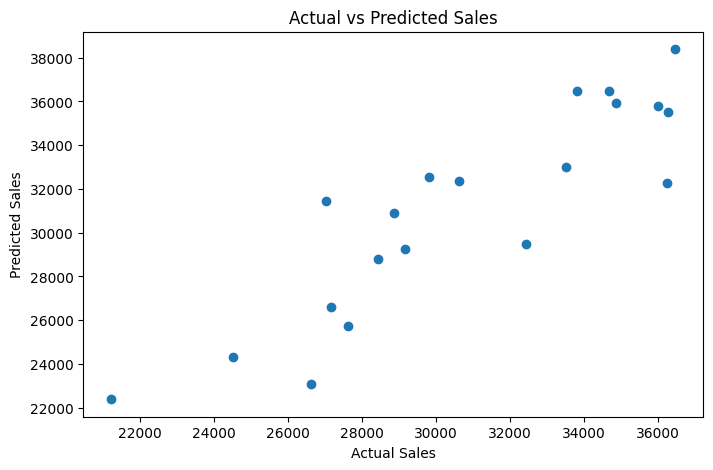

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.show()